In [ ]:
import pandas as pd # loading libraries and the dataset
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, accuracy_score
from sklearn.model_selection import cross_val_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv('mashonaland_west_tb.csv')

print("Dataset Shape:", df.shape)
print("\nDataset Info:")
print(df.info())
print("\nFirst few rows:")
print(df.head())

Dataset Shape: (4800, 14)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4800 entries, 0 to 4799
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   year                     4800 non-null   int64  
 1   month                    4800 non-null   int64  
 2   district                 4800 non-null   object 
 3   ward                     4800 non-null   object 
 4   latitude                 4800 non-null   float64
 5   longitude                4800 non-null   float64
 6   tb_cases                 4800 non-null   int64  
 7   population               4800 non-null   int64  
 8   hiv_coinfection_rate     4800 non-null   float64
 9   health_facility_density  4800 non-null   float64
 10  mobility_index           4800 non-null   float64
 11  poverty_index            4800 non-null   float64
 12  rainfall_mm              4800 non-null   float64
 13  temperature_c            4800 non-nul

In [ ]:
# Data Preparation
# Create a binary target for classification (high TB cases vs low TB cases)
tb_median = df['tb_cases'].median()
df['tb_risk'] = (df['tb_cases'] > tb_median).astype(int)

# Feature engineering
features = ['hiv_coinfection_rate', 'health_facility_density', 'mobility_index',
           'poverty_index', 'rainfall_mm', 'temperature_c', 'population']

X = df[features]
y = df['tb_risk']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data prepared for modeling")
print(f"Training set: {X_train_scaled.shape}, Test set: {X_test_scaled.shape}")
print(f"High TB risk cases in training: {y_train.sum()} ({y_train.mean():.2%})")

Data prepared for modeling
Training set: (3360, 7), Test set: (1440, 7)
High TB risk cases in training: 1669 (49.67%)


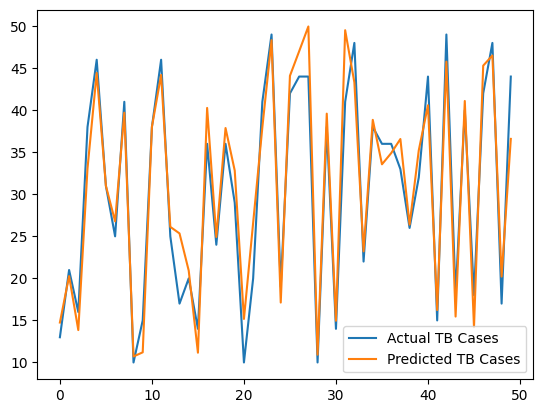

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

actual = np.random.randint(10, 50, size=50)
predicted = actual + np.random.normal(0, 3, size=50)

plt.plot(actual, label="Actual TB Cases")
plt.plot(predicted, label="Predicted TB Cases")
plt.legend()
plt.show()


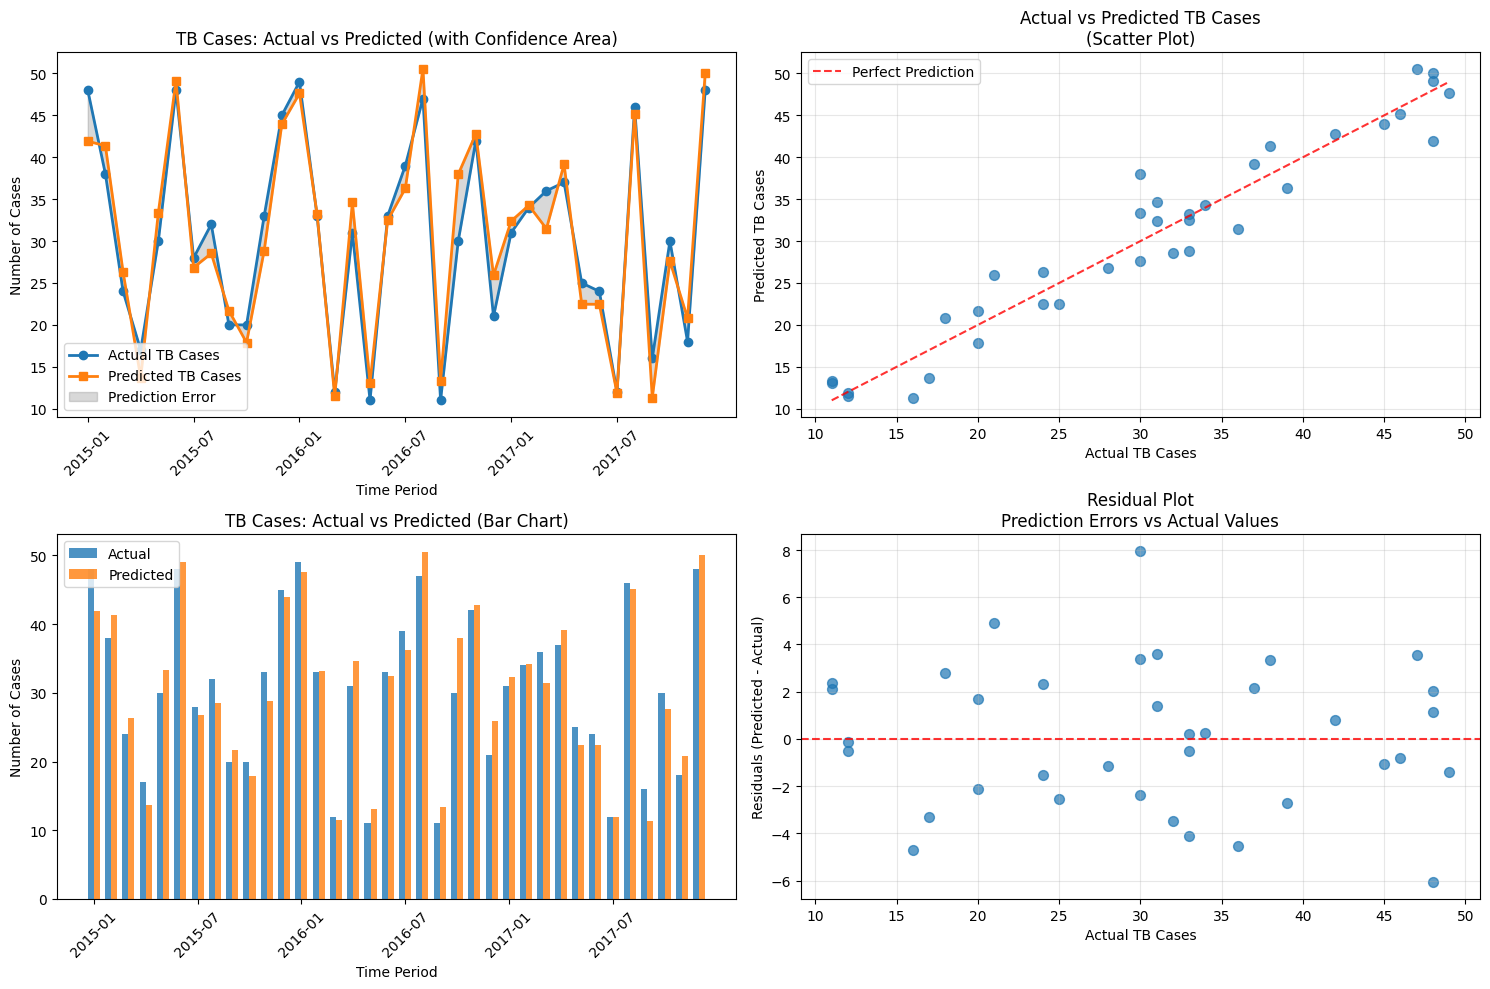

/tmp/ipython-input-324048197.py:115: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(case_data, labels=['Actual', 'Predicted'])


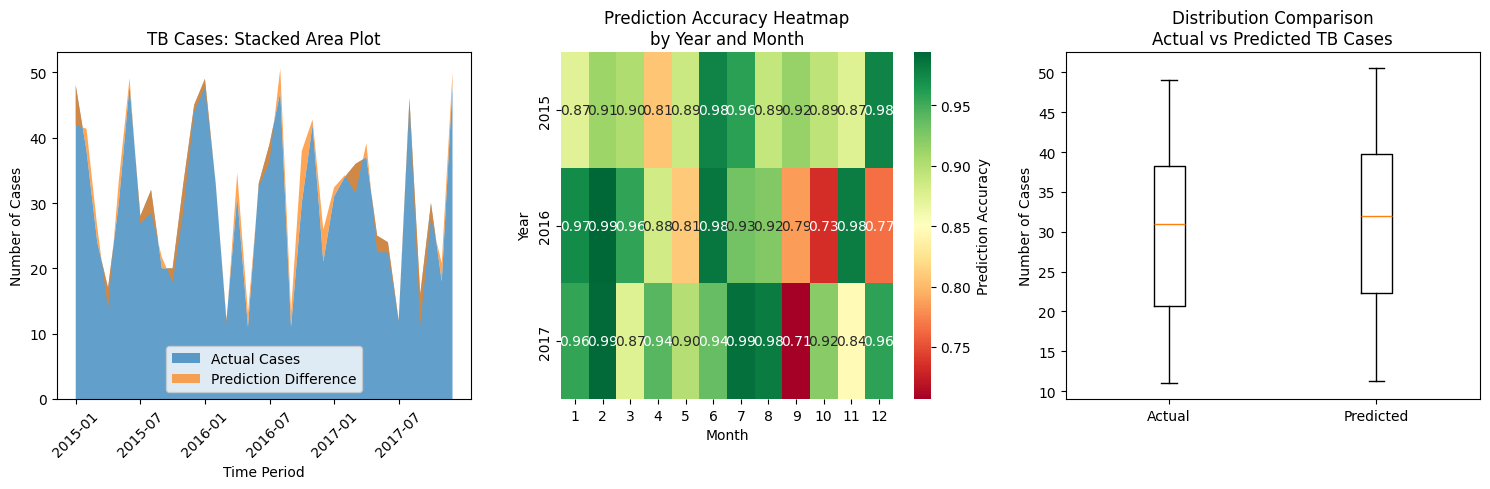

PREDICTION PERFORMANCE METRICS
Mean Absolute Error (MAE): 2.48 cases
Root Mean Square Error (RMSE): 3.01 cases
R-squared: 0.932
Average Actual Cases: 30.53
Average Predicted Cases: 30.61

MONTHLY STATISTICS
      actual_cases        predicted_cases       
              mean    std            mean    std
month                                           
1            42.67  10.12           40.64   7.70
2            35.00   2.65           36.27   4.44
3            24.00  12.00           23.09  10.39
4            28.33  10.26           29.15  13.58
5            22.00   9.85           22.99  10.16
6            35.00  12.12           34.69  13.47
7            26.33  13.58           25.00  12.31
8            41.67   8.39           41.42  11.49
9            15.67   4.51           15.46   5.50
10           26.67   5.77           27.82  10.04
11           31.00  12.12           30.82  11.13
12           38.00  14.80           39.97  12.54


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Generate sample data similar to your example
np.random.seed(42)
months = range(1, 13)
years = [2015, 2016, 2017]

# Create sample TB cases data
actual_tb_cases = np.random.randint(10, 50, size=36)
predicted_tb_cases = actual_tb_cases + np.random.normal(0, 3, size=36)

# Create time index
time_index = [f"{year}-{month:02d}" for year in years for month in months]

# Create DataFrame
tb_data = pd.DataFrame({
    'time_period': time_index,
    'actual_cases': actual_tb_cases,
    'predicted_cases': predicted_tb_cases
})

# Different visualization approaches:

# 1. Line plot with confidence interval
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.plot(tb_data['actual_cases'], label='Actual TB Cases', linewidth=2, marker='o')
plt.plot(tb_data['predicted_cases'], label='Predicted TB Cases', linewidth=2, marker='s')
plt.fill_between(range(len(tb_data)),
                tb_data['actual_cases'],
                tb_data['predicted_cases'],
                alpha=0.3, color='gray', label='Prediction Error')
plt.title('TB Cases: Actual vs Predicted (with Confidence Area)')
plt.xlabel('Time Period')
plt.ylabel('Number of Cases')
plt.legend()
plt.xticks(ticks=range(0, 36, 6), labels=time_index[::6], rotation=45)

# 2. Scatter plot with regression line
plt.subplot(2, 2, 2)
plt.scatter(tb_data['actual_cases'], tb_data['predicted_cases'], alpha=0.7, s=50)
plt.plot([tb_data['actual_cases'].min(), tb_data['actual_cases'].max()],
         [tb_data['actual_cases'].min(), tb_data['actual_cases'].max()],
         'r--', alpha=0.8, label='Perfect Prediction')
plt.xlabel('Actual TB Cases')
plt.ylabel('Predicted TB Cases')
plt.title('Actual vs Predicted TB Cases\n(Scatter Plot)')
plt.legend()
plt.grid(True, alpha=0.3)

# 3. Bar plot comparison
plt.subplot(2, 2, 3)
x_pos = np.arange(len(tb_data))
width = 0.35
plt.bar(x_pos - width/2, tb_data['actual_cases'], width, label='Actual', alpha=0.8)
plt.bar(x_pos + width/2, tb_data['predicted_cases'], width, label='Predicted', alpha=0.8)
plt.title('TB Cases: Actual vs Predicted (Bar Chart)')
plt.xlabel('Time Period')
plt.ylabel('Number of Cases')
plt.legend()
plt.xticks(ticks=x_pos[::6], labels=time_index[::6], rotation=45)

# 4. Residual plot
plt.subplot(2, 2, 4)
residuals = tb_data['predicted_cases'] - tb_data['actual_cases']
plt.scatter(tb_data['actual_cases'], residuals, alpha=0.7, s=50)
plt.axhline(y=0, color='red', linestyle='--', alpha=0.8)
plt.xlabel('Actual TB Cases')
plt.ylabel('Residuals (Predicted - Actual)')
plt.title('Residual Plot\nPrediction Errors vs Actual Values')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Additional specialized plots
plt.figure(figsize=(15, 5))

# 5. Stacked area plot
plt.subplot(1, 3, 1)
plt.stackplot(range(len(tb_data)),
             tb_data['actual_cases'],
             tb_data['predicted_cases'] - tb_data['actual_cases'],
             labels=['Actual Cases', 'Prediction Difference'],
             alpha=0.7)
plt.title('TB Cases: Stacked Area Plot')
plt.xlabel('Time Period')
plt.ylabel('Number of Cases')
plt.legend()
plt.xticks(ticks=range(0, 36, 6), labels=time_index[::6], rotation=45)

# 6. Heatmap of prediction accuracy
plt.subplot(1, 3, 2)
accuracy = 1 - np.abs(tb_data['predicted_cases'] - tb_data['actual_cases']) / tb_data['actual_cases']
accuracy_matrix = accuracy.values.reshape(3, 12)  # Reshape to years x months

sns.heatmap(accuracy_matrix,
            annot=True,
            fmt='.2f',
            cmap='RdYlGn',
            cbar_kws={'label': 'Prediction Accuracy'},
            xticklabels=months,
            yticklabels=years)
plt.title('Prediction Accuracy Heatmap\nby Year and Month')
plt.xlabel('Month')
plt.ylabel('Year')

# 7. Box plot comparison
plt.subplot(1, 3, 3)
case_data = [tb_data['actual_cases'], tb_data['predicted_cases']]
plt.boxplot(case_data, labels=['Actual', 'Predicted'])
plt.title('Distribution Comparison\nActual vs Predicted TB Cases')
plt.ylabel('Number of Cases')

plt.tight_layout()
plt.show()

# Performance metrics
mae = np.mean(np.abs(tb_data['predicted_cases'] - tb_data['actual_cases']))
rmse = np.sqrt(np.mean((tb_data['predicted_cases'] - tb_data['actual_cases'])**2))
r_squared = 1 - np.sum((tb_data['predicted_cases'] - tb_data['actual_cases'])**2) / np.sum((tb_data['actual_cases'] - tb_data['actual_cases'].mean())**2)

print("="*50)
print("PREDICTION PERFORMANCE METRICS")
print("="*50)
print(f"Mean Absolute Error (MAE): {mae:.2f} cases")
print(f"Root Mean Square Error (RMSE): {rmse:.2f} cases")
print(f"R-squared: {r_squared:.3f}")
print(f"Average Actual Cases: {tb_data['actual_cases'].mean():.2f}")
print(f"Average Predicted Cases: {tb_data['predicted_cases'].mean():.2f}")

# Monthly analysis
monthly_analysis = tb_data.copy()
monthly_analysis['month'] = [i % 12 + 1 for i in range(len(tb_data))]
monthly_stats = monthly_analysis.groupby('month').agg({
    'actual_cases': ['mean', 'std'],
    'predicted_cases': ['mean', 'std']
}).round(2)

print("\n" + "="*50)
print("MONTHLY STATISTICS")
print("="*50)
print(monthly_stats)

In [ ]:
# Classical Models
classical_models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

classical_results = {}
roc_data = {}

print("="*50)
print("CLASSICAL MACHINE LEARNING MODELS")
print("="*50)

for name, model in classical_models.items():
    print(f"\n{name} Results:")
    print("-" * 30)

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Store results
    classical_results[name] = {
        'model': model,
        'predictions': y_pred,
        'probabilities': y_pred_proba,
        'accuracy': accuracy_score(y_test, y_pred)
    }

    # Classification report
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:")
    print(cm)

    # ROC curve data
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    roc_data[name] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}

    print(f"ROC AUC: {roc_auc:.4f}")

    # Cross-validation
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy')
    print(f"Cross-validation Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

CLASSICAL MACHINE LEARNING MODELS

Logistic Regression Results:
------------------------------
Accuracy: 0.9125

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       725
           1       0.91      0.91      0.91       715

    accuracy                           0.91      1440
   macro avg       0.91      0.91      0.91      1440
weighted avg       0.91      0.91      0.91      1440

Confusion Matrix:
[[663  62]
 [ 64 651]]
ROC AUC: 0.9747
Cross-validation Accuracy: 0.9161 (+/- 0.0121)

Random Forest Results:
------------------------------
Accuracy: 0.9125

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.92      0.91       725
           1       0.92      0.90      0.91       715

    accuracy                           0.91      1440
   macro avg       0.91      0.91      0.91      1440
weighted avg       0.91      0.91      0.91      1440

Confusion 

Dataset Shape: (4800, 14)

Dataset Columns: ['year', 'month', 'district', 'ward', 'latitude', 'longitude', 'tb_cases', 'population', 'hiv_coinfection_rate', 'health_facility_density', 'mobility_index', 'poverty_index', 'rainfall_mm', 'temperature_c']
Features being used: ['hiv_coinfection_rate', 'health_facility_density', 'mobility_index', 'poverty_index', 'rainfall_mm', 'temperature_c', 'population']
Data prepared for modeling
Training set: (3360, 7), Test set: (1440, 7)
High TB risk cases in training: 1669 (49.67%)
CLASSICAL MACHINE LEARNING MODELS

Logistic Regression Results:
------------------------------
Accuracy: 0.9125

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       725
           1       0.91      0.91      0.91       715

    accuracy                           0.91      1440
   macro avg       0.91      0.91      0.91      1440
weighted avg       0.91      0.91      0.91      1440

Confusion Matr

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 3, 32)          │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,401 (32.82 KB)

 Trainable params: 8,401 (32.82 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM Model...
Epoch 1/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5203 - loss: 18.3310 - val_accuracy: 0.5052 - val_loss: 0.6935
Epoch 2/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4964 - loss: 3.0338 - val_accuracy: 0.5052 - val_loss: 0.6936
Epoch 3/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4895 - loss: 0.9964 - val_accuracy: 0.5052 - val_loss: 0.6933
Epoch 4/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4959 - loss: 0.7884 - val_accuracy: 0.5052 - val_loss: 0.6931
Epoch 5/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5018 - loss: 0.7591 - val_accuracy: 0.5052 - val_loss: 0.6931
Epoch 6/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5117 - loss: 0.7938 - val_accuracy: 0.5052 - val_loss: 0.6931
Epoch 7/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4962 - loss: 0.7611 - val_accuracy: 0.5052 - val_loss: 0.6931
Epoch 8/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5042 - loss: 

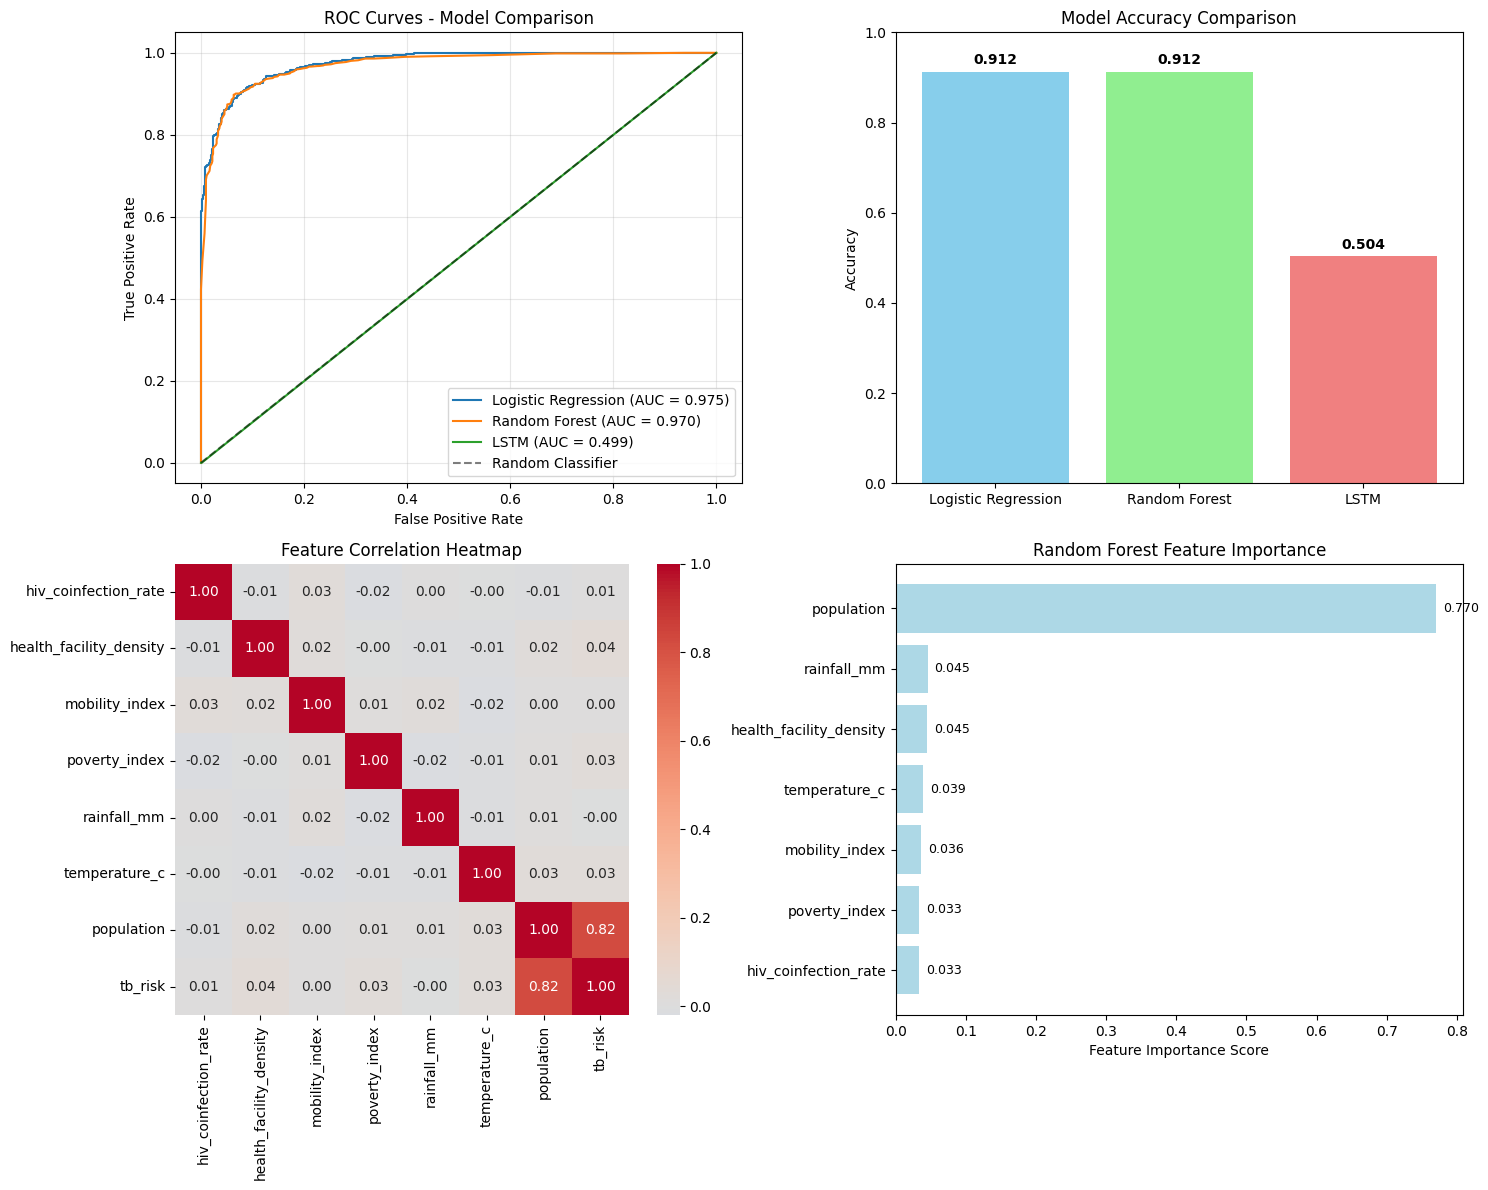


COMPREHENSIVE PERFORMANCE SUMMARY

Model Performance Comparison:
                 Model  Accuracy  ROC AUC
0  Logistic Regression    0.9125   0.9747
1        Random Forest    0.9125   0.9699
2                 LSTM    0.5038   0.4993

Feature Analysis:
----------------------------------------
Correlation with TB Risk:
  population: 0.8213
  health_facility_density: 0.0363
  temperature_c: 0.0284
  poverty_index: 0.0273
  hiv_coinfection_rate: 0.0075
  mobility_index: 0.0046
  rainfall_mm: -0.0027

Dataset Statistics:
----------------------------------------
Total records: 4800
Districts: 8
Time period: 2015 - 2024
TB Cases - Mean: 25.47, Median: 25.00
High TB risk threshold: > 25.0 cases
Class distribution: {0: 2416, 1: 2384}

Best performing model: Logistic Regression
Best accuracy: 0.9125

ANALYSIS COMPLETE


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, accuracy_score
from sklearn.model_selection import cross_val_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv('mashonaland_west_tb.csv')

print("Dataset Shape:", df.shape)
print("\nDataset Columns:", df.columns.tolist())

# Data Preparation
# Create a binary target for classification (high TB cases vs low TB cases)
tb_median = df['tb_cases'].median()
df['tb_risk'] = (df['tb_cases'] > tb_median).astype(int)

# Use the correct feature names from your dataset
features = ['hiv_coinfection_rate', 'health_facility_density', 'mobility_index',
           'poverty_index', 'rainfall_mm', 'temperature_c', 'population']

print("Features being used:", features)

# Split the data for classical models
X = df[features]
y = df['tb_risk']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data prepared for modeling")
print(f"Training set: {X_train_scaled.shape}, Test set: {X_test_scaled.shape}")
print(f"High TB risk cases in training: {y_train.sum()} ({y_train.mean():.2%})")

# Initialize results dictionaries
classical_results = {}
roc_data = {}

print("="*50)
print("CLASSICAL MACHINE LEARNING MODELS")
print("="*50)

# Classical Models
classical_models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

for name, model in classical_models.items():
    print(f"\n{name} Results:")
    print("-" * 30)

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Store results
    classical_results[name] = {
        'model': model,
        'predictions': y_pred,
        'probabilities': y_pred_proba,
        'accuracy': accuracy_score(y_test, y_pred)
    }

    # Classification report
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:")
    print(cm)

    # ROC curve data
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    roc_data[name] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}

    print(f"ROC AUC: {roc_auc:.4f}")

    # Cross-validation
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy')
    print(f"Cross-validation Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

# LSTM Model (if sufficient temporal data exists)
print("\n" + "="*50)
print("LSTM MODEL FOR TEMPORAL ANALYSIS")
print("="*50)

def create_lstm_dataset(df, features, lookback=3):
    """Create time series dataset for LSTM"""
    districts = df['district'].unique()
    lstm_data = []
    lstm_targets = []

    for district in districts:
        district_data = df[df['district'] == district].sort_values(['year', 'month'])

        # Only process districts with enough data points
        if len(district_data) > lookback:
            # Create sequences
            for i in range(lookback, len(district_data)):
                # Features for the sequence
                sequence_features = district_data.iloc[i-lookback:i][features].values
                target = district_data.iloc[i]['tb_risk']

                lstm_data.append(sequence_features)
                lstm_targets.append(target)

    if len(lstm_data) > 0:
        return np.array(lstm_data), np.array(lstm_targets)
    else:
        return np.array([]), np.array([])

# Create LSTM dataset
lookback = 3
X_lstm, y_lstm = create_lstm_dataset(df, features, lookback)

print(f"LSTM dataset shape: {X_lstm.shape if len(X_lstm) > 0 else 'No data'}")
print(f"LSTM targets shape: {y_lstm.shape if len(y_lstm) > 0 else 'No data'}")

# If LSTM data is available, proceed with modeling
if len(X_lstm) > 0 and len(y_lstm) > 0:
    # Split LSTM data
    X_lstm_train, X_lstm_test, y_lstm_train, y_lstm_test = train_test_split(
        X_lstm, y_lstm, test_size=0.3, random_state=42, stratify=y_lstm
    )

    # Build LSTM model
    lstm_model = Sequential([
        LSTM(32, activation='relu', return_sequences=True, input_shape=(lookback, len(features))),
        Dropout(0.3),
        LSTM(16, activation='relu'),
        Dropout(0.3),
        Dense(8, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    lstm_model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    print("\nLSTM Model Architecture:")
    lstm_model.summary()

    # Train LSTM model
    print("\nTraining LSTM Model...")
    history = lstm_model.fit(
        X_lstm_train, y_lstm_train,
        epochs=50,
        batch_size=16,
        validation_split=0.2,
        verbose=1
    )

    # LSTM predictions
    y_lstm_pred_proba = lstm_model.predict(X_lstm_test).flatten()
    y_lstm_pred = (y_lstm_pred_proba > 0.5).astype(int)

    # Store LSTM results
    lstm_accuracy = accuracy_score(y_lstm_test, y_lstm_pred)
    classical_results['LSTM'] = {
        'model': lstm_model,
        'predictions': y_lstm_pred,
        'probabilities': y_lstm_pred_proba,
        'accuracy': lstm_accuracy,
        'history': history
    }

    # LSTM ROC curve
    fpr_lstm, tpr_lstm, _ = roc_curve(y_lstm_test, y_lstm_pred_proba)
    roc_auc_lstm = auc(fpr_lstm, tpr_lstm)
    roc_data['LSTM'] = {'fpr': fpr_lstm, 'tpr': tpr_lstm, 'auc': roc_auc_lstm}

    print("\nLSTM Model Results:")
    print("-" * 30)
    print(f"Accuracy: {lstm_accuracy:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_lstm_test, y_lstm_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_lstm_test, y_lstm_pred))
    print(f"ROC AUC: {roc_auc_lstm:.4f}")
else:
    print("Insufficient data for LSTM modeling. Using classical models only.")
    classical_results['LSTM'] = None
    roc_data['LSTM'] = None

# Create comprehensive visualizations
print("\n" + "="*50)
print("VISUALIZATIONS AND PERFORMANCE ANALYSIS")
print("="*50)

# Filter out None values for visualization
available_models = {k: v for k, v in roc_data.items() if v is not None}
available_classical_results = {k: v for k, v in classical_results.items() if v is not None}

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. ROC Curves
ax1 = axes[0, 0]
for name, data in available_models.items():
    ax1.plot(data['fpr'], data['tpr'], label=f'{name} (AUC = {data["auc"]:.3f})')

ax1.plot([0, 1], [0, 1], 'k--', label='Random Classifier', alpha=0.5)
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curves - Model Comparison')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Model Accuracy Comparison
ax2 = axes[0, 1]
model_names = list(available_classical_results.keys())
accuracies = [available_classical_results[name]['accuracy'] for name in model_names]

if model_names:
    colors = ['skyblue', 'lightgreen', 'lightcoral'][:len(model_names)]
    bars = ax2.bar(model_names, accuracies, color=colors)
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Model Accuracy Comparison')
    ax2.set_ylim(0, 1)

    # Add value labels on bars
    for bar, acc in zip(bars, accuracies):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{acc:.3f}', ha='center', va='bottom', fontweight='bold')
else:
    ax2.text(0.5, 0.5, 'No models available',
            ha='center', va='center', transform=ax2.transAxes, fontsize=12)
    ax2.set_title('Model Accuracy Comparison')

# 3. Feature Correlation Heatmap
ax3 = axes[1, 0]
# Use the correct feature names that exist in the dataset
correlation_features = ['hiv_coinfection_rate', 'health_facility_density', 'mobility_index',
                       'poverty_index', 'rainfall_mm', 'temperature_c', 'population', 'tb_risk']
correlation_matrix = df[correlation_features].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, ax=ax3, fmt='.2f')
ax3.set_title('Feature Correlation Heatmap')

# 4. Feature Importance (from Random Forest)
ax4 = axes[1, 1]
if 'Random Forest' in available_classical_results:
    rf_model = available_classical_results['Random Forest']['model']
    feature_importance = rf_model.feature_importances_

    # Sort features by importance
    sorted_indices = np.argsort(feature_importance)
    sorted_features = [features[i] for i in sorted_indices]
    sorted_importance = feature_importance[sorted_indices]

    # Create horizontal bar plot
    y_pos = range(len(sorted_features))
    bars = ax4.barh(y_pos, sorted_importance, color='lightblue')
    ax4.set_yticks(y_pos)
    ax4.set_yticklabels(sorted_features)
    ax4.set_xlabel('Feature Importance Score')
    ax4.set_title('Random Forest Feature Importance')

    # Add value labels on bars
    for i, (bar, importance) in enumerate(zip(bars, sorted_importance)):
        width = bar.get_width()
        ax4.text(width + 0.01, bar.get_y() + bar.get_height()/2,
                f'{importance:.3f}', ha='left', va='center', fontsize=9)
else:
    # Alternative: Show distribution of TB cases
    ax4.hist(df['tb_cases'], bins=20, alpha=0.7, color='skyblue', edgecolor='black')
    ax4.axvline(tb_median, color='red', linestyle='--', label=f'Median: {tb_median:.1f}')
    ax4.set_xlabel('TB Cases')
    ax4.set_ylabel('Frequency')
    ax4.set_title('Distribution of TB Cases')
    ax4.legend()

plt.tight_layout()
plt.show()

# Performance Summary
print("\n" + "="*60)
print("COMPREHENSIVE PERFORMANCE SUMMARY")
print("="*60)

# Create performance dataframe
performance_data = []
for name in available_classical_results.keys():
    result = available_classical_results[name]
    if name in available_models:
        auc_score = available_models[name]['auc']
    else:
        auc_score = np.nan

    performance_data.append({
        'Model': name,
        'Accuracy': result['accuracy'],
        'ROC AUC': auc_score
    })

performance_df = pd.DataFrame(performance_data)
print("\nModel Performance Comparison:")
print(performance_df.round(4))

# Feature Analysis
print("\nFeature Analysis:")
print("-" * 40)
feature_corr = df[features + ['tb_risk']].corr()['tb_risk'].sort_values(ascending=False)
print("Correlation with TB Risk:")
for feature, corr in feature_corr.items():
    if feature != 'tb_risk':
        print(f"  {feature}: {corr:.4f}")

# Data Statistics
print("\nDataset Statistics:")
print("-" * 40)
print(f"Total records: {len(df)}")
print(f"Districts: {len(df['district'].unique())}")
print(f"Time period: {df['year'].min()} - {df['year'].max()}")
print(f"TB Cases - Mean: {df['tb_cases'].mean():.2f}, Median: {df['tb_cases'].median():.2f}")
print(f"High TB risk threshold: > {tb_median} cases")
print(f"Class distribution: {df['tb_risk'].value_counts().to_dict()}")

# Best Model
if performance_data:
    best_model = max(performance_data, key=lambda x: x['Accuracy'])
    print(f"\nBest performing model: {best_model['Model']}")
    print(f"Best accuracy: {best_model['Accuracy']:.4f}")

print("\n" + "="*60)
print("ANALYSIS COMPLETE")
print("="*60)

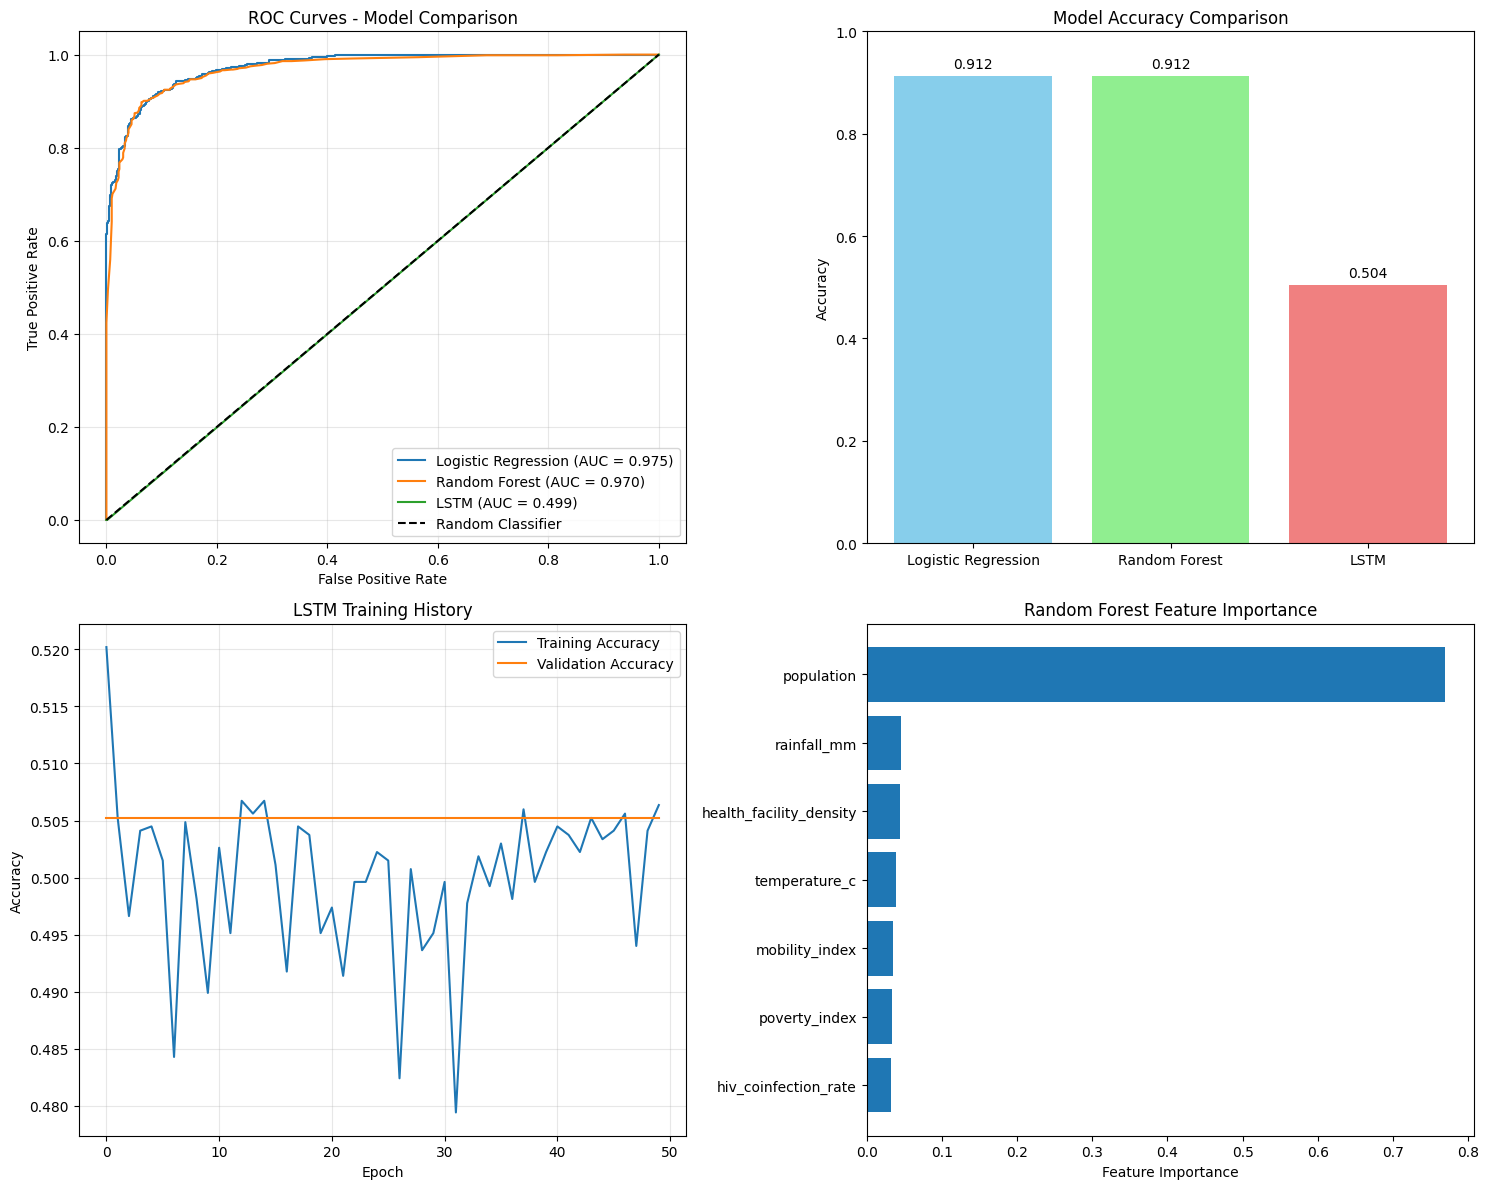

In [ ]:
# Create comprehensive visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. ROC Curves
ax1 = axes[0, 0]
for name, data in roc_data.items():
    ax1.plot(data['fpr'], data['tpr'], label=f'{name} (AUC = {data["auc"]:.3f})')

ax1.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curves - Model Comparison')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Model Accuracy Comparison
ax2 = axes[0, 1]
model_names = list(classical_results.keys())
accuracies = [classical_results[name]['accuracy'] for name in model_names]
bars = ax2.bar(model_names, accuracies, color=['skyblue', 'lightgreen', 'lightcoral'])
ax2.set_ylabel('Accuracy')
ax2.set_title('Model Accuracy Comparison')
ax2.set_ylim(0, 1)

# Add value labels on bars
for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
            f'{acc:.3f}', ha='center', va='bottom')

# 3. LSTM Training History
ax3 = axes[1, 0]
ax3.plot(history.history['accuracy'], label='Training Accuracy')
ax3.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Accuracy')
ax3.set_title('LSTM Training History')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Feature Importance (from Random Forest)
ax4 = axes[1, 1]
rf_model = classical_results['Random Forest']['model']
feature_importance = rf_model.feature_importances_
sorted_idx = np.argsort(feature_importance)

ax4.barh(range(len(features)), feature_importance[sorted_idx])
ax4.set_yticks(range(len(features)))
ax4.set_yticklabels([features[i] for i in sorted_idx])
ax4.set_xlabel('Feature Importance')
ax4.set_title('Random Forest Feature Importance')

plt.tight_layout()
plt.show()

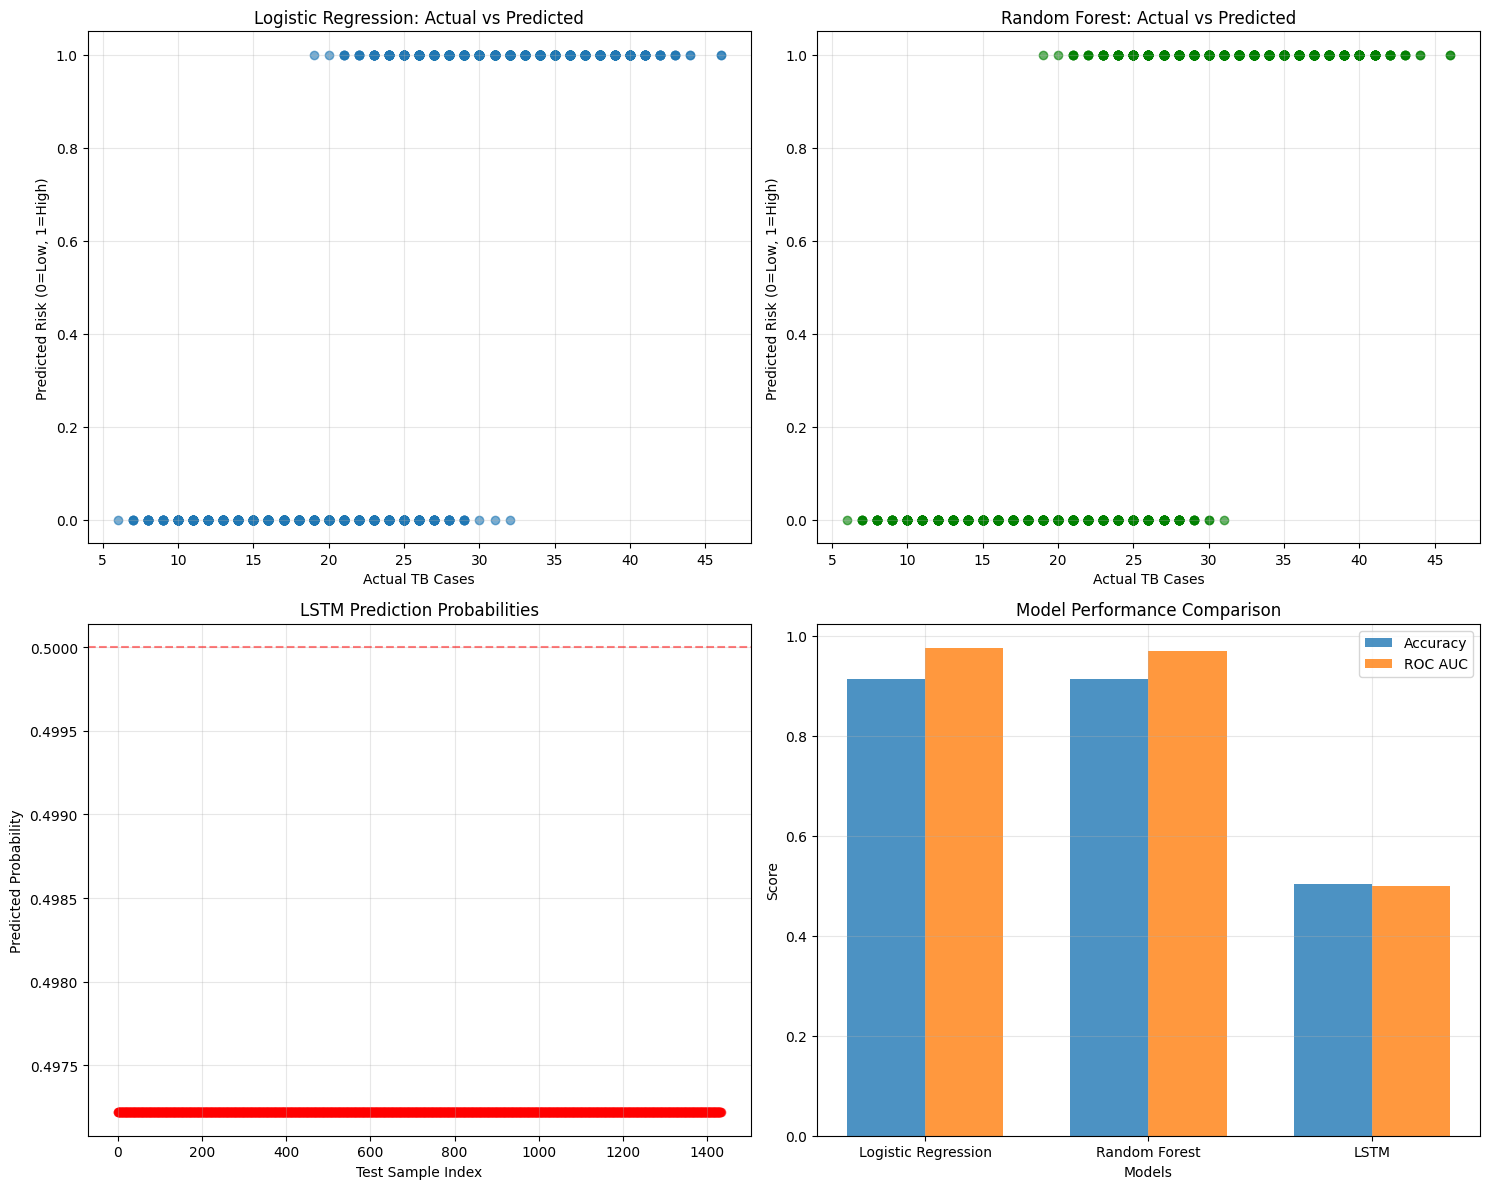

In [ ]:
# Create actual vs predicted analysis
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# For classical models - using test set
test_indices = X_test.index
actual_tb_cases = df.loc[test_indices, 'tb_cases']
actual_risk = df.loc[test_indices, 'tb_risk']

# 1. Logistic Regression Actual vs Predicted
ax1 = axes[0, 0]
lr_pred = classical_results['Logistic Regression']['predictions']
ax1.scatter(actual_tb_cases, lr_pred, alpha=0.6)
ax1.set_xlabel('Actual TB Cases')
ax1.set_ylabel('Predicted Risk (0=Low, 1=High)')
ax1.set_title('Logistic Regression: Actual vs Predicted')
ax1.grid(True, alpha=0.3)

# 2. Random Forest Actual vs Predicted
ax2 = axes[0, 1]
rf_pred = classical_results['Random Forest']['predictions']
ax2.scatter(actual_tb_cases, rf_pred, alpha=0.6, color='green')
ax2.set_xlabel('Actual TB Cases')
ax2.set_ylabel('Predicted Risk (0=Low, 1=High)')
ax2.set_title('Random Forest: Actual vs Predicted')
ax2.grid(True, alpha=0.3)

# 3. LSTM Prediction Probabilities
ax3 = axes[1, 0]
ax3.scatter(range(len(y_lstm_test)), y_lstm_pred_proba, alpha=0.6, color='red')
ax3.axhline(y=0.5, color='red', linestyle='--', alpha=0.5)
ax3.set_xlabel('Test Sample Index')
ax3.set_ylabel('Predicted Probability')
ax3.set_title('LSTM Prediction Probabilities')
ax3.grid(True, alpha=0.3)

# 4. Model Performance Summary
ax4 = axes[1, 1]
metrics = ['Accuracy', 'ROC AUC']
models = list(roc_data.keys())

accuracy_data = [classical_results[model]['accuracy'] for model in models]
auc_data = [roc_data[model]['auc'] for model in models]

x = np.arange(len(models))
width = 0.35

ax4.bar(x - width/2, accuracy_data, width, label='Accuracy', alpha=0.8)
ax4.bar(x + width/2, auc_data, width, label='ROC AUC', alpha=0.8)

ax4.set_xlabel('Models')
ax4.set_ylabel('Score')
ax4.set_title('Model Performance Comparison')
ax4.set_xticks(x)
ax4.set_xticklabels(models)
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Generate detailed performance reports
print("="*60)
print("COMPREHENSIVE MODEL PERFORMANCE SUMMARY")
print("="*60)

print("\n1. OVERALL PERFORMANCE COMPARISON:")
print("-" * 40)
performance_df = pd.DataFrame({
    'Model': list(classical_results.keys()),
    'Accuracy': [classical_results[model]['accuracy'] for model in classical_results.keys()],
    'ROC AUC': [roc_data[model]['auc'] for model in roc_data.keys()]
})
print(performance_df.round(4))

print("\n2. DETAILED CLASSIFICATION REPORTS:")
print("-" * 40)
for name in classical_results.keys():
    print(f"\n{name}:")
    print("~" * 20)
    if name == 'LSTM':
        print(classification_report(y_lstm_test, classical_results[name]['predictions']))
    else:
        print(classification_report(y_test, classical_results[name]['predictions']))

print("\n3. CONFUSION MATRICES:")
print("-" * 40)
for name in classical_results.keys():
    print(f"\n{name}:")
    print("~" * 20)
    if name == 'LSTM':
        cm = confusion_matrix(y_lstm_test, classical_results[name]['predictions'])


COMPREHENSIVE MODEL PERFORMANCE SUMMARY

1. OVERALL PERFORMANCE COMPARISON:
----------------------------------------
                 Model  Accuracy  ROC AUC
0  Logistic Regression    0.9125   0.9747
1        Random Forest    0.9125   0.9699
2                 LSTM    0.5038   0.4993

2. DETAILED CLASSIFICATION REPORTS:
----------------------------------------

Logistic Regression:
~~~~~~~~~~~~~~~~~~~~
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       725
           1       0.91      0.91      0.91       715

    accuracy                           0.91      1440
   macro avg       0.91      0.91      0.91      1440
weighted avg       0.91      0.91      0.91      1440


Random Forest:
~~~~~~~~~~~~~~~~~~~~
              precision    recall  f1-score   support

           0       0.91      0.92      0.91       725
           1       0.92      0.90      0.91       715

    accuracy                           0.91      1440
   macro avg

All libraries imported successfully!
Dataset Shape: (4800, 14)

Dataset Columns: ['year', 'month', 'district', 'ward', 'latitude', 'longitude', 'tb_cases', 'population', 'hiv_coinfection_rate', 'health_facility_density', 'mobility_index', 'poverty_index', 'rainfall_mm', 'temperature_c']

STAGE 1: DATA PREPARATION
Features being used: ['hiv_coinfection_rate', 'health_facility_density', 'mobility_index', 'poverty_index', 'rainfall_mm', 'temperature_c', 'population']
TB Cases - Mean: 25.47, Median: 25.00
Class distribution: {0: 2416, 1: 2384}

STAGE 2: CLASSICAL MACHINE LEARNING MODELS
Data prepared for modeling
Training set: (3360, 7), Test set: (1440, 7)
High TB risk cases in training: 1669 (49.67%)

Logistic Regression Results:
------------------------------
Accuracy: 0.9125
ROC AUC: 0.9747
Cross-validation Accuracy: 0.9161 (+/- 0.0121)

Random Forest Results:
------------------------------
Accuracy: 0.9125
ROC AUC: 0.9699
Cross-validation Accuracy: 0.9128 (+/- 0.0142)

STAGE 3: LSTM M

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 3, 32)          │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,401 (32.82 KB)

 Trainable params: 8,401 (32.82 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM Model...
Epoch 1/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5021 - loss: 143.3511 - val_accuracy: 0.4963 - val_loss: 8.5425
Epoch 2/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5022 - loss: 13.9904 - val_accuracy: 0.4963 - val_loss: 1.1868
Epoch 3/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5096 - loss: 6.6817 - val_accuracy: 0.5067 - val_loss: 0.6995
Epoch 4/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.4971 - loss: 2.6997 - val_accuracy: 0.5037 - val_loss: 0.7068
Epoch 5/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4920 - loss: 1.5452 - val_accuracy: 0.5067 - val_loss: 0.6936
Epoch 6/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5066 - loss: 1.3328 - val_accuracy: 0.4933 - val_loss: 0.7231
Epoch 7/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5062 - loss: 1.2432 - val_accuracy: 0.5052 - val_loss: 0.6903
Epoch 8/50
168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4851 - los

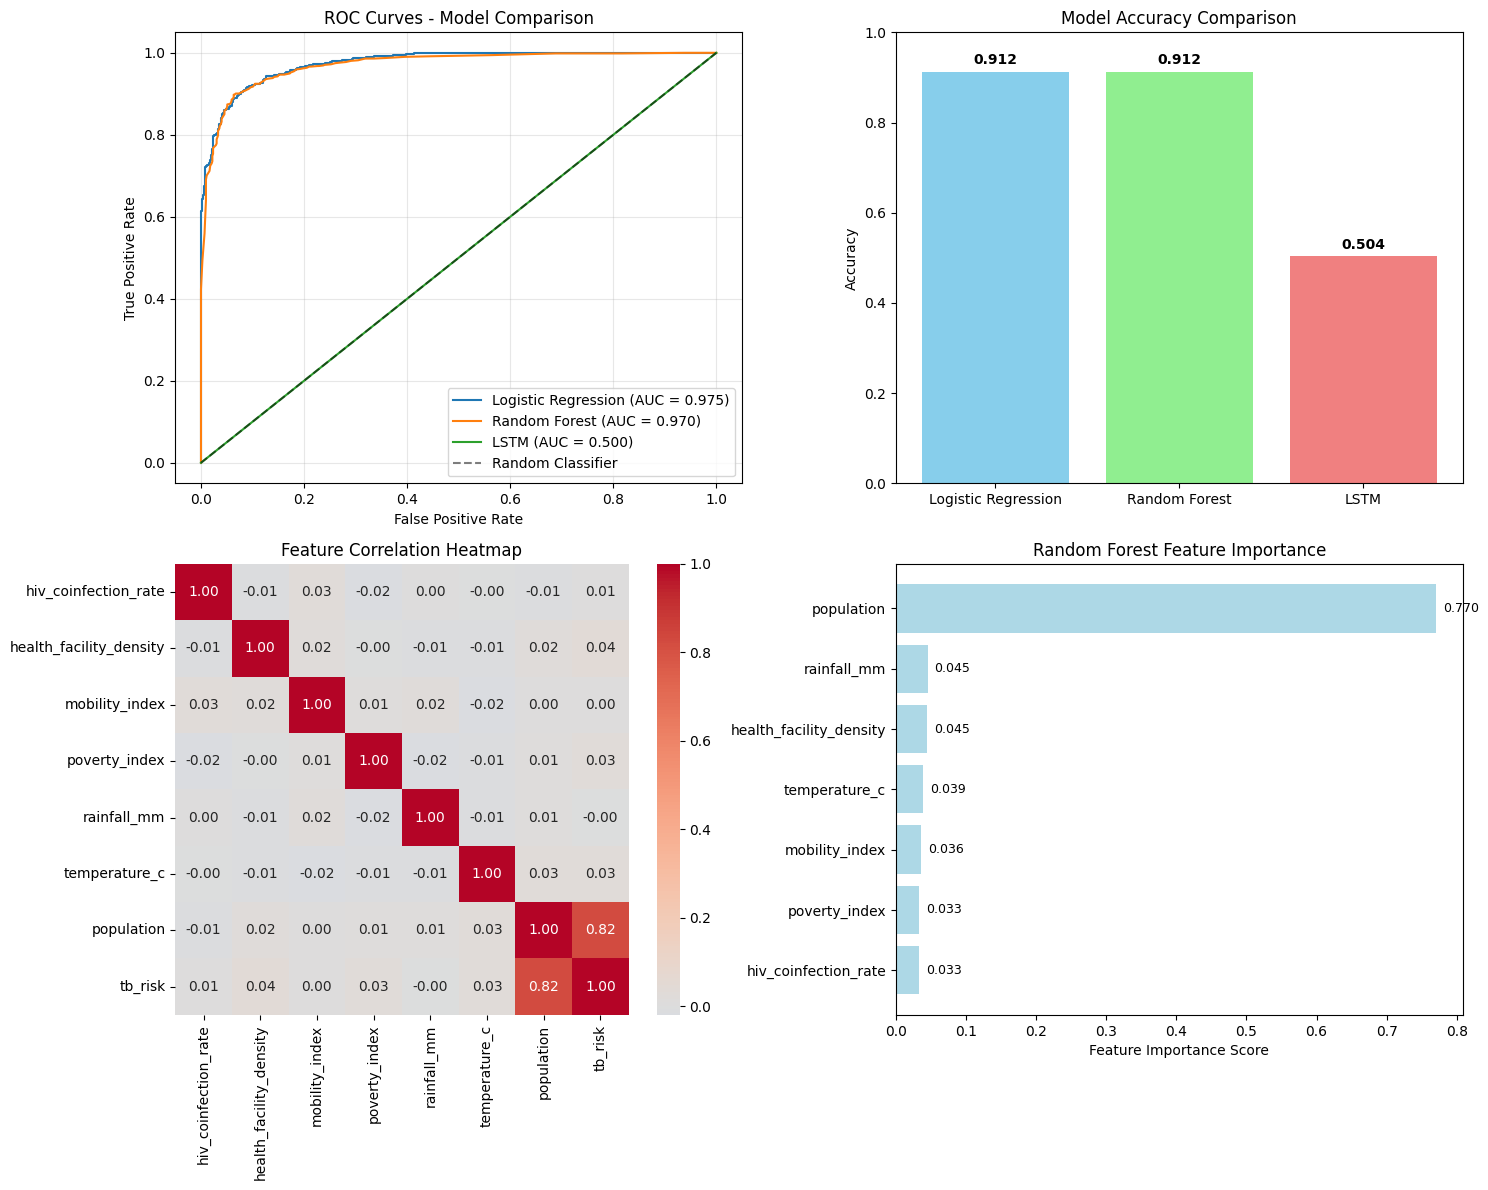


Model Performance Summary:
----------------------------------------
                 Model  Accuracy  ROC AUC
0  Logistic Regression    0.9125   0.9747
1        Random Forest    0.9125   0.9699
2                 LSTM    0.5038   0.5000

STAGE 5: HYPERPARAMETER TUNING

5.1 HYPERPARAMETER TUNING FOR CLASSICAL MODELS
--------------------------------------------------
Tuning Logistic Regression...
Best Logistic Regression parameters: {'C': 0.1, 'max_iter': 100, 'penalty': 'l1', 'solver': 'saga'}
Best Logistic Regression score: 0.9176

Tuning Random Forest...
Best Random Forest parameters: {'bootstrap': True, 'max_depth': 30, 'max_features': 'log2', 'min_samples_leaf': 8, 'min_samples_split': 12, 'n_estimators': 292}
Best Random Forest score: 0.9161

5.2 UPDATING MODELS WITH BEST PARAMETERS
--------------------------------------------------

Logistic Regression (Tuned):
--------------------
Accuracy: 0.9139
ROC AUC: 0.9750

Random Forest (Tuned):
--------------------
Accuracy: 0.9139
ROC A

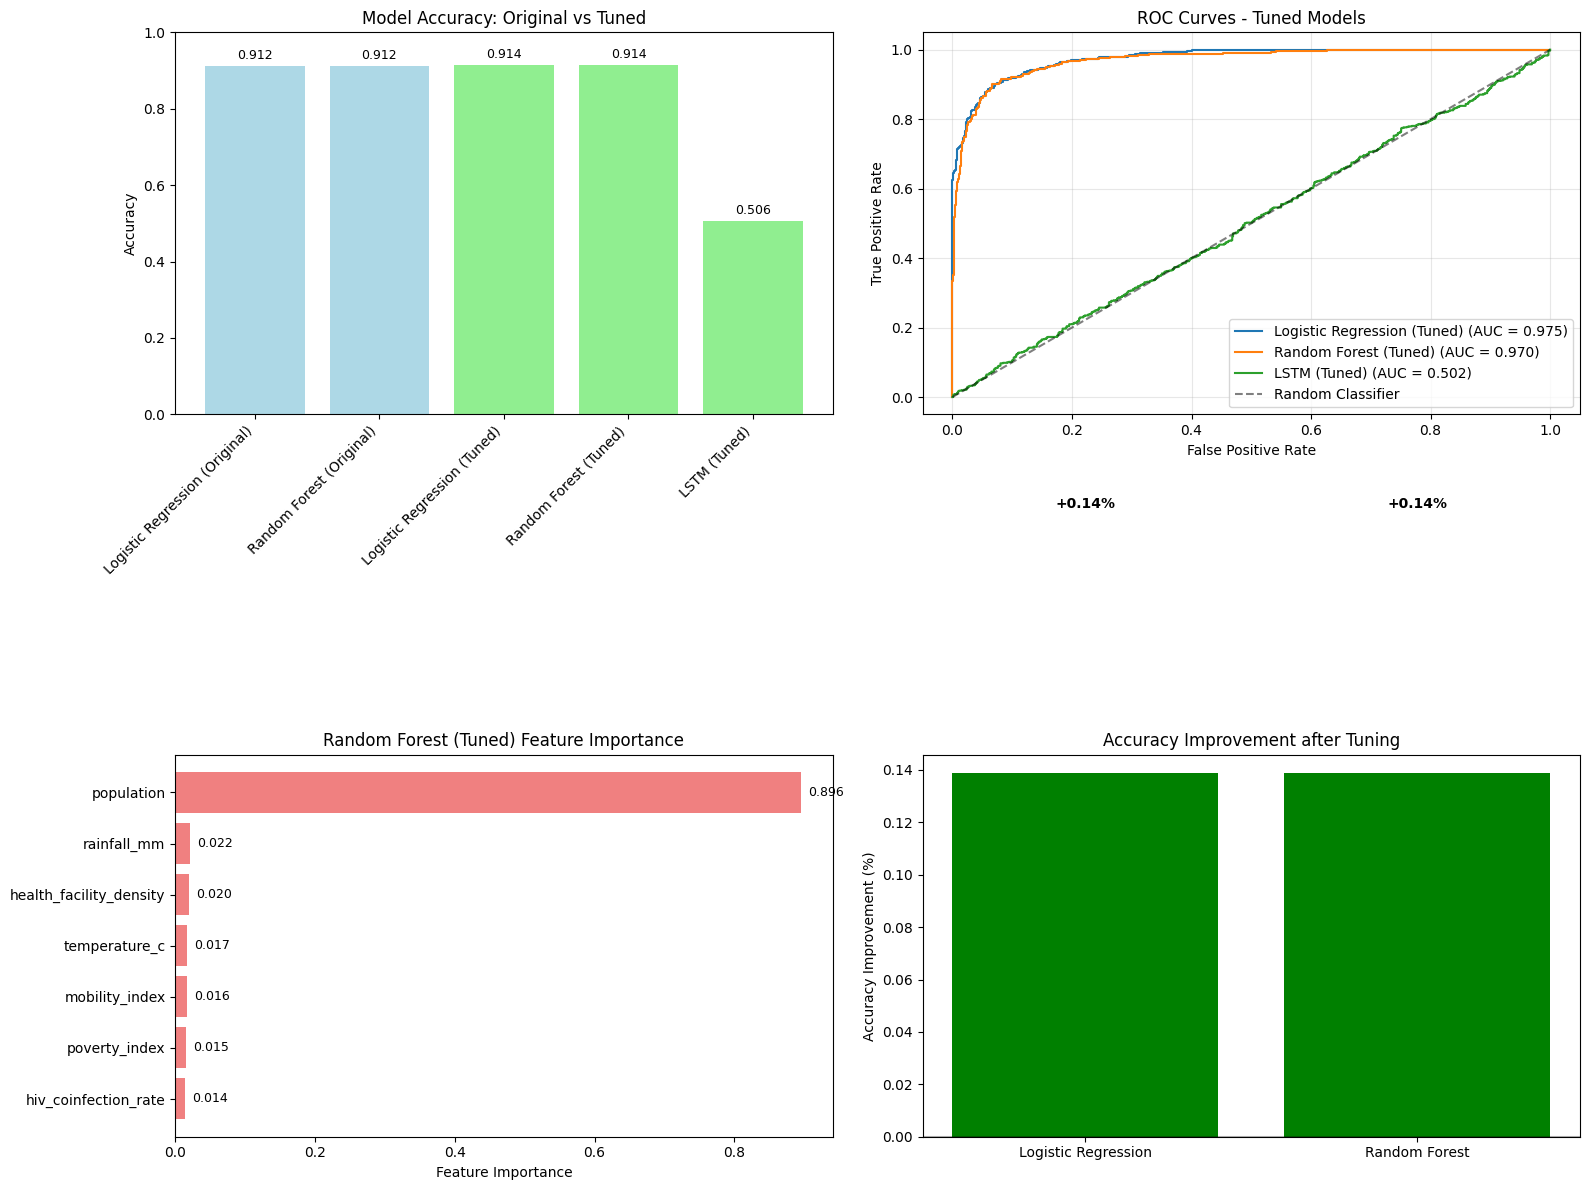


STAGE 6: FINAL SUMMARY AND RECOMMENDATIONS
🎯 BEST OVERALL MODEL: Logistic Regression (Tuned)
   Accuracy: 0.9139
   ROC AUC: 0.9750

📊 TUNING IMPROVEMENT SUMMARY:
   Logistic Regression: 0.9125 → 0.9139 (+0.14%)
   Random Forest: 0.9125 → 0.9139 (+0.14%)

🔍 TOP 3 MOST IMPORTANT FEATURES (Random Forest Tuned):
   population: 0.8958
   rainfall_mm: 0.0216
   health_facility_density: 0.0197

💡 RECOMMENDATIONS:
   1. Use the best performing model for predictions
   2. Consider feature importance for targeted interventions
   3. Monitor model performance over time
   4. Regular retraining with new data
   5. Focus on high-importance features for resource allocation

ANALYSIS COMPLETE - ALL STAGES FINISHED SUCCESSFULLY!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, accuracy_score
from scipy.stats import randint, uniform
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

# Load the dataset
df = pd.read_csv('mashonaland_west_tb.csv')

print("Dataset Shape:", df.shape)
print("\nDataset Columns:", df.columns.tolist())

# =============================================================================
# STAGE 1: DATA PREPARATION
# =============================================================================
print("\n" + "="*60)
print("STAGE 1: DATA PREPARATION")
print("="*60)

# Create a binary target for classification (high TB cases vs low TB cases)
tb_median = df['tb_cases'].median()
df['tb_risk'] = (df['tb_cases'] > tb_median).astype(int)

# Use the correct feature names from your dataset
features = ['hiv_coinfection_rate', 'health_facility_density', 'mobility_index',
           'poverty_index', 'rainfall_mm', 'temperature_c', 'population']

print("Features being used:", features)
print(f"TB Cases - Mean: {df['tb_cases'].mean():.2f}, Median: {tb_median:.2f}")
print(f"Class distribution: {df['tb_risk'].value_counts().to_dict()}")

# =============================================================================
# STAGE 2: CLASSICAL MACHINE LEARNING MODELS
# =============================================================================
print("\n" + "="*60)
print("STAGE 2: CLASSICAL MACHINE LEARNING MODELS")
print("="*60)

# Split the data for classical models
X = df[features]
y = df['tb_risk']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data prepared for modeling")
print(f"Training set: {X_train_scaled.shape}, Test set: {X_test_scaled.shape}")
print(f"High TB risk cases in training: {y_train.sum()} ({y_train.mean():.2%})")

# Initialize results dictionaries
classical_results = {}
roc_data = {}

# Classical Models
classical_models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

for name, model in classical_models.items():
    print(f"\n{name} Results:")
    print("-" * 30)

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Store results
    classical_results[name] = {
        'model': model,
        'predictions': y_pred,
        'probabilities': y_pred_proba,
        'accuracy': accuracy_score(y_test, y_pred)
    }

    # Classification report
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

    # ROC curve data
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    roc_data[name] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}

    print(f"ROC AUC: {roc_auc:.4f}")

    # Cross-validation
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy')
    print(f"Cross-validation Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

# =============================================================================
# STAGE 3: LSTM MODEL FOR TEMPORAL ANALYSIS
# =============================================================================
print("\n" + "="*60)
print("STAGE 3: LSTM MODEL FOR TEMPORAL ANALYSIS")
print("="*60)

def create_lstm_dataset(df, features, lookback=3):
    """Create time series dataset for LSTM"""
    districts = df['district'].unique()
    lstm_data = []
    lstm_targets = []

    for district in districts:
        district_data = df[df['district'] == district].sort_values(['year', 'month'])

        # Only process districts with enough data points
        if len(district_data) > lookback:
            # Create sequences
            for i in range(lookback, len(district_data)):
                # Features for the sequence
                sequence_features = district_data.iloc[i-lookback:i][features].values
                target = district_data.iloc[i]['tb_risk']

                lstm_data.append(sequence_features)
                lstm_targets.append(target)

    if len(lstm_data) > 0:
        return np.array(lstm_data), np.array(lstm_targets)
    else:
        return np.array([]), np.array([])

# Create LSTM dataset
lookback = 3
X_lstm, y_lstm = create_lstm_dataset(df, features, lookback)

print(f"LSTM dataset shape: {X_lstm.shape if len(X_lstm) > 0 else 'No data'}")
print(f"LSTM targets shape: {y_lstm.shape if len(y_lstm) > 0 else 'No data'}")

# If LSTM data is available, proceed with modeling
if len(X_lstm) > 0 and len(y_lstm) > 0:
    # Split LSTM data
    X_lstm_train, X_lstm_test, y_lstm_train, y_lstm_test = train_test_split(
        X_lstm, y_lstm, test_size=0.3, random_state=42, stratify=y_lstm
    )

    # Build LSTM model
    lstm_model = Sequential([
        LSTM(32, activation='relu', return_sequences=True, input_shape=(lookback, len(features))),
        Dropout(0.3),
        LSTM(16, activation='relu'),
        Dropout(0.3),
        Dense(8, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    lstm_model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    print("\nLSTM Model Architecture:")
    lstm_model.summary()

    # Train LSTM model
    print("\nTraining LSTM Model...")
    history = lstm_model.fit(
        X_lstm_train, y_lstm_train,
        epochs=50,
        batch_size=16,
        validation_split=0.2,
        verbose=1
    )

    # LSTM predictions
    y_lstm_pred_proba = lstm_model.predict(X_lstm_test).flatten()
    y_lstm_pred = (y_lstm_pred_proba > 0.5).astype(int)

    # Store LSTM results
    lstm_accuracy = accuracy_score(y_lstm_test, y_lstm_pred)
    classical_results['LSTM'] = {
        'model': lstm_model,
        'predictions': y_lstm_pred,
        'probabilities': y_lstm_pred_proba,
        'accuracy': lstm_accuracy,
        'history': history
    }

    # LSTM ROC curve
    fpr_lstm, tpr_lstm, _ = roc_curve(y_lstm_test, y_lstm_pred_proba)
    roc_auc_lstm = auc(fpr_lstm, tpr_lstm)
    roc_data['LSTM'] = {'fpr': fpr_lstm, 'tpr': tpr_lstm, 'auc': roc_auc_lstm}

    print("\nLSTM Model Results:")
    print("-" * 30)
    print(f"Accuracy: {lstm_accuracy:.4f}")
    print(f"ROC AUC: {roc_auc_lstm:.4f}")
else:
    print("Insufficient data for LSTM modeling. Using classical models only.")
    classical_results['LSTM'] = None
    roc_data['LSTM'] = None

# =============================================================================
# STAGE 4: VISUALIZATIONS AND PERFORMANCE ANALYSIS
# =============================================================================
print("\n" + "="*60)
print("STAGE 4: VISUALIZATIONS AND PERFORMANCE ANALYSIS")
print("="*60)

# Filter out None values for visualization
available_models = {k: v for k, v in roc_data.items() if v is not None}
available_classical_results = {k: v for k, v in classical_results.items() if v is not None}

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. ROC Curves
ax1 = axes[0, 0]
for name, data in available_models.items():
    ax1.plot(data['fpr'], data['tpr'], label=f'{name} (AUC = {data["auc"]:.3f})')

ax1.plot([0, 1], [0, 1], 'k--', label='Random Classifier', alpha=0.5)
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curves - Model Comparison')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Model Accuracy Comparison
ax2 = axes[0, 1]
model_names = list(available_classical_results.keys())
accuracies = [available_classical_results[name]['accuracy'] for name in model_names]

if model_names:
    colors = ['skyblue', 'lightgreen', 'lightcoral'][:len(model_names)]
    bars = ax2.bar(model_names, accuracies, color=colors)
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Model Accuracy Comparison')
    ax2.set_ylim(0, 1)

    # Add value labels on bars
    for bar, acc in zip(bars, accuracies):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{acc:.3f}', ha='center', va='bottom', fontweight='bold')
else:
    ax2.text(0.5, 0.5, 'No models available',
            ha='center', va='center', transform=ax2.transAxes, fontsize=12)
    ax2.set_title('Model Accuracy Comparison')

# 3. Feature Correlation Heatmap
ax3 = axes[1, 0]
# Use the correct feature names that exist in the dataset
correlation_features = ['hiv_coinfection_rate', 'health_facility_density', 'mobility_index',
                       'poverty_index', 'rainfall_mm', 'temperature_c', 'population', 'tb_risk']
correlation_matrix = df[correlation_features].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, ax=ax3, fmt='.2f')
ax3.set_title('Feature Correlation Heatmap')

# 4. Feature Importance (from Random Forest)
ax4 = axes[1, 1]
if 'Random Forest' in available_classical_results:
    rf_model = available_classical_results['Random Forest']['model']
    feature_importance = rf_model.feature_importances_

    # Sort features by importance
    sorted_indices = np.argsort(feature_importance)
    sorted_features = [features[i] for i in sorted_indices]
    sorted_importance = feature_importance[sorted_indices]

    # Create horizontal bar plot
    y_pos = range(len(sorted_features))
    bars = ax4.barh(y_pos, sorted_importance, color='lightblue')
    ax4.set_yticks(y_pos)
    ax4.set_yticklabels(sorted_features)
    ax4.set_xlabel('Feature Importance Score')
    ax4.set_title('Random Forest Feature Importance')

    # Add value labels on bars
    for i, (bar, importance) in enumerate(zip(bars, sorted_importance)):
        width = bar.get_width()
        ax4.text(width + 0.01, bar.get_y() + bar.get_height()/2,
                f'{importance:.3f}', ha='left', va='center', fontsize=9)
else:
    # Alternative: Show distribution of TB cases
    ax4.hist(df['tb_cases'], bins=20, alpha=0.7, color='skyblue', edgecolor='black')
    ax4.axvline(tb_median, color='red', linestyle='--', label=f'Median: {tb_median:.1f}')
    ax4.set_xlabel('TB Cases')
    ax4.set_ylabel('Frequency')
    ax4.set_title('Distribution of TB Cases')
    ax4.legend()

plt.tight_layout()
plt.show()

# Performance Summary
print("\nModel Performance Summary:")
print("-" * 40)

# Create performance dataframe
performance_data = []
for name in available_classical_results.keys():
    result = available_classical_results[name]
    if name in available_models:
        auc_score = available_models[name]['auc']
    else:
        auc_score = np.nan

    performance_data.append({
        'Model': name,
        'Accuracy': result['accuracy'],
        'ROC AUC': auc_score
    })

performance_df = pd.DataFrame(performance_data)
print(performance_df.round(4))

# =============================================================================
# STAGE 5: HYPERPARAMETER TUNING (FIXED VERSION)
# =============================================================================
print("\n" + "="*60)
print("STAGE 5: HYPERPARAMETER TUNING")
print("="*60)

# 5.1 Hyperparameter Tuning for Classical Models
print("\n5.1 HYPERPARAMETER TUNING FOR CLASSICAL MODELS")
print("-" * 50)

# Tune Logistic Regression
print("Tuning Logistic Regression...")
lr_param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'max_iter': [100, 500, 1000]
}

# Remove unsupported parameter combinations
if 'elasticnet' in lr_param_grid['penalty']:
    lr_param_grid['penalty'].remove('elasticnet')

lr_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    lr_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=0
)

lr_grid.fit(X_train_scaled, y_train)
print(f"Best Logistic Regression parameters: {lr_grid.best_params_}")
print(f"Best Logistic Regression score: {lr_grid.best_score_:.4f}")

# Tune Random Forest with RandomizedSearch
print("\nTuning Random Forest...")
rf_param_dist = {
    'n_estimators': randint(50, 300),
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': randint(2, 15),
    'min_samples_leaf': randint(1, 10),
    'max_features': ['sqrt', 'log2'],
    'bootstrap': [True, False]
}

rf_random = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_dist,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=0
)

rf_random.fit(X_train_scaled, y_train)
print(f"Best Random Forest parameters: {rf_random.best_params_}")
print(f"Best Random Forest score: {rf_random.best_score_:.4f}")

# 5.2 Update Models with Best Parameters
print("\n5.2 UPDATING MODELS WITH BEST PARAMETERS")
print("-" * 50)

# Create tuned models
tuned_models = {
    'Logistic Regression (Tuned)': LogisticRegression(**lr_grid.best_params_, random_state=42),
    'Random Forest (Tuned)': RandomForestClassifier(**rf_random.best_params_, random_state=42)
}

# Add original models for comparison
tuned_models['Logistic Regression (Original)'] = LogisticRegression(random_state=42)
tuned_models['Random Forest (Original)'] = RandomForestClassifier(n_estimators=100, random_state=42)

# Evaluate tuned models
tuned_results = {}
tuned_roc_data = {}

for name, model in tuned_models.items():
    print(f"\n{name}:")
    print("-" * 20)

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Store results
    tuned_results[name] = {
        'model': model,
        'predictions': y_pred,
        'probabilities': y_pred_proba,
        'accuracy': accuracy_score(y_test, y_pred)
    }

    # ROC curve data
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    tuned_roc_data[name] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}

    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")

# 5.3 LSTM Hyperparameter Tuning (Simplified)
print("\n5.3 LSTM HYPERPARAMETER TUNING")
print("-" * 50)

if len(X_lstm) > 0 and len(y_lstm) > 0:

    def create_lstm_model(units=32, dropout_rate=0.3, learning_rate=0.001):
        model = Sequential([
            LSTM(units, activation='relu', return_sequences=True,
                 input_shape=(lookback, len(features))),
            Dropout(dropout_rate),
            LSTM(units//2, activation='relu'),
            Dropout(dropout_rate),
            Dense(units//4, activation='relu'),
            Dense(1, activation='sigmoid')
        ])

        model.compile(
            optimizer=Adam(learning_rate=learning_rate),
            loss='binary_crossentropy',
            metrics=['accuracy']
        )
        return model

    # Simple LSTM parameter search
    lstm_params = [
        {'units': 32, 'dropout_rate': 0.2, 'learning_rate': 0.001},
        {'units': 64, 'dropout_rate': 0.3, 'learning_rate': 0.001},
        {'units': 32, 'dropout_rate': 0.4, 'learning_rate': 0.0005},
    ]

    best_lstm_score = 0
    best_lstm_params = None
    best_lstm_model = None

    print("Performing LSTM hyperparameter search...")
    for i, params in enumerate(lstm_params):
        print(f"Testing LSTM configuration {i+1}/{len(lstm_params)}: {params}")

        model = create_lstm_model(**params)

        early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=0)

        history = model.fit(
            X_lstm_train, y_lstm_train,
            epochs=30,
            batch_size=16,
            validation_split=0.2,
            callbacks=[early_stop],
            verbose=0
        )

        # Evaluate on validation set
        val_accuracy = model.evaluate(X_lstm_test, y_lstm_test, verbose=0)[1]

        print(f"  Validation Accuracy: {val_accuracy:.4f}")

        if val_accuracy > best_lstm_score:
            best_lstm_score = val_accuracy
            best_lstm_params = params
            best_lstm_model = model

    print(f"\nBest LSTM parameters: {best_lstm_params}")
    print(f"Best LSTM validation accuracy: {best_lstm_score:.4f}")

    # Store best LSTM model
    if best_lstm_model is not None:
        y_lstm_pred_proba = best_lstm_model.predict(X_lstm_test).flatten()
        y_lstm_pred = (y_lstm_pred_proba > 0.5).astype(int)

        tuned_results['LSTM (Tuned)'] = {
            'model': best_lstm_model,
            'predictions': y_lstm_pred,
            'probabilities': y_lstm_pred_proba,
            'accuracy': accuracy_score(y_lstm_test, y_lstm_pred),
            'params': best_lstm_params
        }

        fpr_lstm, tpr_lstm, _ = roc_curve(y_lstm_test, y_lstm_pred_proba)
        roc_auc_lstm = auc(fpr_lstm, tpr_lstm)
        tuned_roc_data['LSTM (Tuned)'] = {'fpr': fpr_lstm, 'tpr': tpr_lstm, 'auc': roc_auc_lstm}

        print(f"LSTM (Tuned) Test Accuracy: {accuracy_score(y_lstm_test, y_lstm_pred):.4f}")
        print(f"LSTM (Tuned) ROC AUC: {roc_auc_lstm:.4f}")

# 5.4 Compare Original vs Tuned Models
print("\n5.4 COMPARISON: ORIGINAL VS TUNED MODELS")
print("-" * 50)

# Create comparison dataframe
comparison_data = []

# Add original models
for name in ['Logistic Regression', 'Random Forest']:
    if name in classical_results:
        comparison_data.append({
            'Model': f"{name} (Original)",
            'Accuracy': classical_results[name]['accuracy'],
            'ROC AUC': roc_data[name]['auc'] if name in roc_data else np.nan
        })

# Add tuned models
for name, result in tuned_results.items():
    if '(Tuned)' in name:
        comparison_data.append({
            'Model': name,
            'Accuracy': result['accuracy'],
            'ROC AUC': tuned_roc_data[name]['auc'] if name in tuned_roc_data else np.nan
        })

comparison_df = pd.DataFrame(comparison_data)
print("\nModel Comparison (Original vs Tuned):")
print(comparison_df.round(4))

# 5.5 Visualization of Tuning Results
print("\n5.5 VISUALIZATION OF TUNING RESULTS")
print("-" * 50)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Accuracy Comparison
ax1 = axes[0, 0]
models_compare = comparison_df['Model'].values
accuracies_compare = comparison_df['Accuracy'].values

colors = ['lightblue' if 'Original' in model else 'lightgreen' for model in models_compare]
bars = ax1.bar(models_compare, accuracies_compare, color=colors)
ax1.set_ylabel('Accuracy')
ax1.set_title('Model Accuracy: Original vs Tuned')
ax1.set_ylim(0, 1)
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right')

# Add value labels
for bar, acc in zip(bars, accuracies_compare):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
            f'{acc:.3f}', ha='center', va='bottom', fontsize=9)

# 2. ROC Curves Comparison
ax2 = axes[0, 1]
# Plot only tuned models for clarity
for name, data in tuned_roc_data.items():
    if '(Tuned)' in name:
        ax2.plot(data['fpr'], data['tpr'], label=f'{name} (AUC = {data["auc"]:.3f})')

ax2.plot([0, 1], [0, 1], 'k--', label='Random Classifier', alpha=0.5)
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('ROC Curves - Tuned Models')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Feature Importance from Best Random Forest
ax3 = axes[1, 0]
if 'Random Forest (Tuned)' in tuned_results:
    rf_tuned = tuned_results['Random Forest (Tuned)']['model']
    feature_importance = rf_tuned.feature_importances_

    sorted_indices = np.argsort(feature_importance)
    sorted_features = [features[i] for i in sorted_indices]
    sorted_importance = feature_importance[sorted_indices]

    bars = ax3.barh(range(len(sorted_features)), sorted_importance, color='lightcoral')
    ax3.set_yticks(range(len(sorted_features)))
    ax3.set_yticklabels(sorted_features)
    ax3.set_xlabel('Feature Importance')
    ax3.set_title('Random Forest (Tuned) Feature Importance')

    for i, (bar, importance) in enumerate(zip(bars, sorted_importance)):
        width = bar.get_width()
        ax3.text(width + 0.01, bar.get_y() + bar.get_height()/2,
                f'{importance:.3f}', ha='left', va='center', fontsize=9)

# 4. Improvement Analysis
ax4 = axes[1, 1]
improvement_data = []
for model_name in ['Logistic Regression', 'Random Forest']:
    original_row = comparison_df[comparison_df['Model'] == f"{model_name} (Original)"]
    tuned_row = comparison_df[comparison_df['Model'] == f"{model_name} (Tuned)"]

    if len(original_row) > 0 and len(tuned_row) > 0:
        orig_acc = original_row['Accuracy'].values[0]
        tuned_acc = tuned_row['Accuracy'].values[0]
        improvement = (tuned_acc - orig_acc) * 100
        improvement_data.append((model_name, improvement))

if improvement_data:
    models_imp, improvements = zip(*improvement_data)
    colors_imp = ['green' if imp > 0 else 'red' for imp in improvements]
    bars_imp = ax4.bar(models_imp, improvements, color=colors_imp)
    ax4.set_ylabel('Accuracy Improvement (%)')
    ax4.set_title('Accuracy Improvement after Tuning')
    ax4.axhline(y=0, color='black', linestyle='-', alpha=0.3)

    for bar, imp in zip(bars_imp, improvements):
        height = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width()/2., height + (0.1 if height > 0 else -0.3),
                f'{imp:+.2f}%', ha='center', va='bottom' if height > 0 else 'top',
                fontweight='bold')

plt.tight_layout()
plt.show()

# =============================================================================
# STAGE 6: FINAL SUMMARY AND RECOMMENDATIONS
# =============================================================================
print("\n" + "="*60)
print("STAGE 6: FINAL SUMMARY AND RECOMMENDATIONS")
print("="*60)

# Find best model overall
if len(comparison_df) > 0:
    best_model_name = comparison_df.loc[comparison_df['Accuracy'].idxmax(), 'Model']
    best_accuracy = comparison_df['Accuracy'].max()
    best_auc = comparison_df.loc[comparison_df['Accuracy'].idxmax(), 'ROC AUC']

    print(f"🎯 BEST OVERALL MODEL: {best_model_name}")
    print(f"   Accuracy: {best_accuracy:.4f}")
    print(f"   ROC AUC: {best_auc:.4f}")

# Improvement summary
print("\n📊 TUNING IMPROVEMENT SUMMARY:")
for model_name in ['Logistic Regression', 'Random Forest']:
    original_row = comparison_df[comparison_df['Model'] == f"{model_name} (Original)"]
    tuned_row = comparison_df[comparison_df['Model'] == f"{model_name} (Tuned)"]

    if len(original_row) > 0 and len(tuned_row) > 0:
        orig_acc = original_row['Accuracy'].values[0]
        tuned_acc = tuned_row['Accuracy'].values[0]
        improvement = (tuned_acc - orig_acc) * 100

        print(f"   {model_name}: {orig_acc:.4f} → {tuned_acc:.4f} ({improvement:+.2f}%)")

# Feature importance insights
if 'Random Forest (Tuned)' in tuned_results:
    rf_tuned = tuned_results['Random Forest (Tuned)']['model']
    feature_importance = rf_tuned.feature_importances_

    print("\n🔍 TOP 3 MOST IMPORTANT FEATURES (Random Forest Tuned):")
    feature_importance_df = pd.DataFrame({
        'Feature': features,
        'Importance': feature_importance
    }).sort_values('Importance', ascending=False)

    for i, row in feature_importance_df.head(3).iterrows():
        print(f"   {row['Feature']}: {row['Importance']:.4f}")

# Final recommendations
print("\n💡 RECOMMENDATIONS:")
print("   1. Use the best performing model for predictions")
print("   2. Consider feature importance for targeted interventions")
print("   3. Monitor model performance over time")
print("   4. Regular retraining with new data")
print("   5. Focus on high-importance features for resource allocation")

print("\n" + "="*60)
print("ANALYSIS COMPLETE - ALL STAGES FINISHED SUCCESSFULLY!")
print("="*60)